In [32]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

album = pd.read_csv("Album.csv")
artist= pd.read_csv("Artist.csv")
customer = pd.read_csv("Customer.csv")
employee = pd.read_csv("Employee.csv")
genre = pd.read_csv("Genre.csv")
invoice = pd.read_csv("Invoice.csv")
invoice_line = pd.read_csv("InvoiceLine.csv")
media = pd.read_csv("MediaType.csv")
playlist = pd.read_csv("Playlist.csv")
playlist_track = pd.read_csv("PlayListTrack.csv")
track = pd.read_csv("Track.csv")
invoice["InvoiceDate"] = pd.to_datetime(invoice["InvoiceDate"])
invoice["Anio"] = invoice["InvoiceDate"].dt.year
invoice["Mes"] = invoice["InvoiceDate"].dt.month

# Con el DataFrame customer, haz un countplot horizontal del número de clientes por país ordenado de mayor a menor

<Axes: xlabel='count', ylabel='Country'>

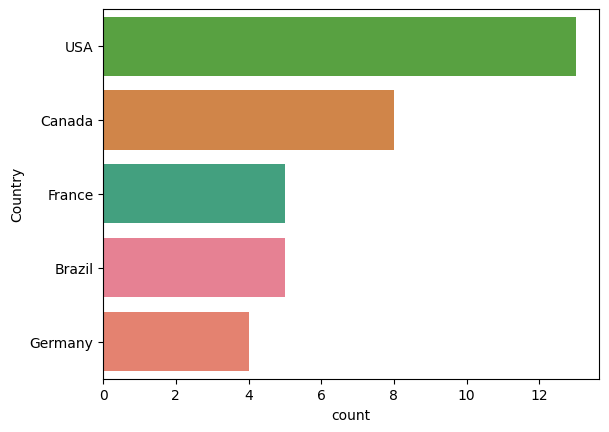

In [33]:
df1 = customer.groupby("Country")["CustomerId"].count().sort_values(ascending = False).nlargest(5).index
sns.countplot(data = customer,y="Country", order = df1, hue = "Country")

# Haz un boxplot del Total de las facturas por país, solo para los 5 países con más ingresos. ¿Algún país tiene facturas atípicamente grandes?

<Axes: xlabel='BillingCountry', ylabel='Total'>

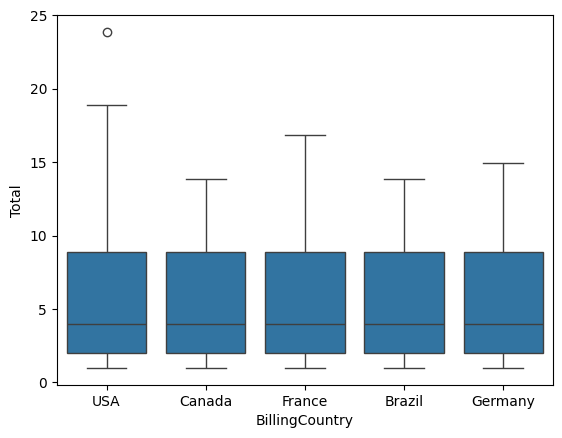

In [34]:
df2 = invoice.groupby("BillingCountry")["Total"].count().sort_values(ascending = False).nlargest(5).index
sns.boxplot(data = invoice,order=df2,x="BillingCountry",y="Total")

# Une invoice con customer (por CustomerId) y luego con employee (SupportRepId de customer de corresponde a EmployeeId; usa left_on/right_on) y grafica con barplot los ingresos totales  que atiende cada representante de soporte

<Axes: xlabel='SupportRepId', ylabel='Total'>

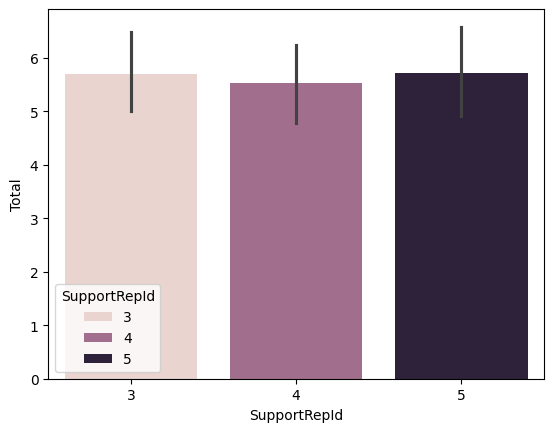

In [35]:
merge = invoice.merge(customer, on = "CustomerId", how = "left")
merge2 = merge.merge(employee, left_on="SupportRepId", right_on="EmployeeId", how = "left")
sns.barplot(data = merge2, y = "Total", x = "SupportRepId", hue = "SupportRepId")

# Crea una figura de 1 x 2 con sharey = True: a la izquierda el violinplot de duración para "Rock" y "Latin"; a la derecha el stripplot de los mismos datos

<Axes: xlabel='Name_x', ylabel='Milliseconds'>

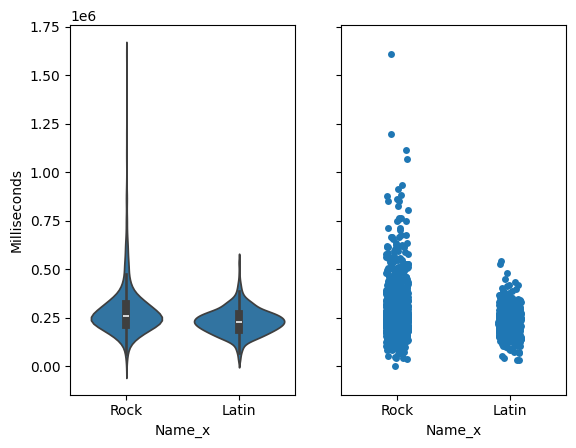

In [36]:
df4 = genre.merge(track, on = "GenreId", how = "left")
df4 = df4[(df4["Name_x"]=="Rock") | (df4["Name_x"] == "Latin" )]
fig, axes = plt.subplots(1, 2, sharey=True)
sns.violinplot(data=df4, x = "Name_x", y ="Milliseconds", ax = axes[0])
sns.stripplot(data=df4, x = "Name_x", y ="Milliseconds", ax = axes[1])

# Construye un table de 2 x 3 con seis gráficas distintas de Chinook. Cada panel debe tener título, etiquetas de ejes en español y la figuraun suptitle. Guárdalo como PNG a 200 dpi

In [37]:
invoice["año"] = invoice["InvoiceDate"].dt.year
invoice["mes"] = invoice["InvoiceDate"].dt.month
mensual = invoice.groupby(["año","mes"], as_index=False)["Total"].sum()

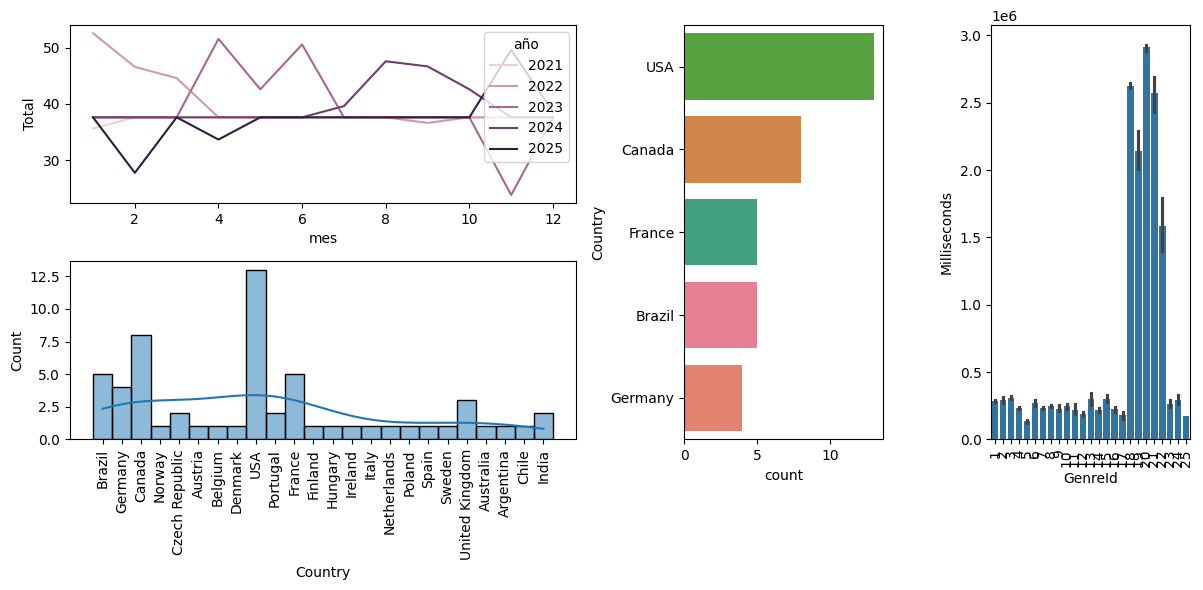

In [38]:
fig, axd = plt.subplot_mosaic("AABC;DDBC" , figsize=(12,6))
troca = track
sns.barplot(data = track, x="GenreId", y="Milliseconds", ax=axd["C"] )

df1 = customer.groupby("Country")["CustomerId"].count().sort_values(ascending = False).nlargest(5).index
sns.countplot(data = customer,y="Country", order = df1, hue = "Country", ax=axd["B"])
sns.lineplot(data= mensual,x="mes", y="Total", hue="año", ax=axd["A"])
sns.histplot(data=customer,x="Country",kde=True,bins=50 ,ax=axd["D"])

axd["D"].tick_params(axis="x",rotation=90)
axd["C"].tick_params(axis="x",rotation=90)
fig.tight_layout()


In [39]:
album

,AlbumId,Title,ArtistId
0,1,For Those About To Rock We Salute You,1
1,2,Balls to the Wall,2
2,3,Restless and Wild,2
3,4,Let There Be Rock,1
4,5,Big Ones,3
...,...,...,...
342,343,Respighi:Pines of Rome,226
343,344,Schubert: The Late String Quartets & String Qu...,272
344,345,Monteverdi: L'Orfeo,273
345,346,Mozart: Chamber Music,274


# Reproduce el heatmap de país x año, pero con el número de facturas en lugar del ingreso (aggfunc = "count"). ¿Cambia la historia?

<Axes: xlabel='año', ylabel='BillingCountry'>

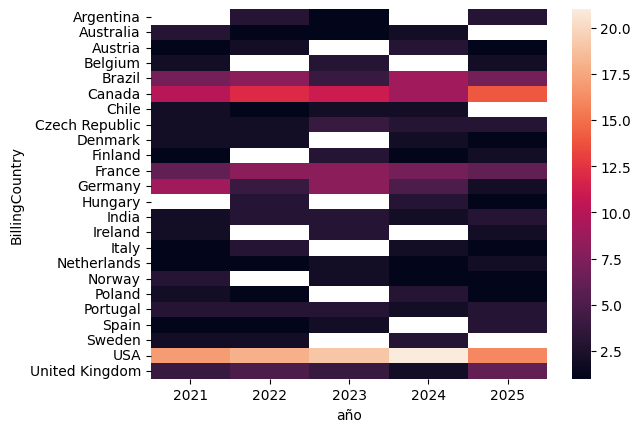

In [40]:
df6=invoice
df6["InvoiceDate"]=pd.to_datetime(df6["InvoiceDate"])
df6["año"]=df6["InvoiceDate"].dt.year
df6=df6.pivot_table(
    values="InvoiceId",
    columns="año",
    index="BillingCountry",
    aggfunc="count"
)

sns.heatmap(df6)